# Praktikum Data Science
## Nama: Muhammad Arif Hermawan Nim: 123240063 Kelas: IF-A

## Latihan Responsi: Klasifikasi dan Prediksi (Regresi)

**Studi Kasus:** Analisis Kimia Wine untuk Kontrol Kualitas
**Dataset:** `wine_latihan.csv` (hasil analisis kimia wine dari tiga kultivar, dibuat "kotor" untuk latihan)

**Catatan:** Bagian A (Klasifikasi) adalah materi yang akan diujikan pada responsi. Bagian B (Prediksi) adalah latihan tambahan dan tidak diujikan pada responsi.

## 1. Import Library

In [33]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.pipeline import Pipeline
from sklearn.svm import SVC
from sklearn.metrics import confusion_matrix, classification_report
from sklearn.ensemble import RandomForestClassifier

## 2. Load Dataset

Muat dataset `wine_latihan.csv` ke dalam DataFrame.

**Tugas:**
- Baca dataset.
- Tampilkan 5 baris pertama.
- Tampilkan informasi umum dataset.

In [5]:
df = pd.read_csv('wine_latihan.csv')
print("Tampilkan 5 baris pertama")
display(df.head(5))

print("\nInformsi umum dataset")
print(df.info())

Tampilkan 5 baris pertama


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280_od315,proline,cultivar
0,13.05,5.80,2.13,21.5,86.0,2.62,2.65,0.30,2.01,2.60,0.73,3.10,380.0,2.0
1,12.25,4.72,2.54,21.0,89.0,1.38,0.47,0.53,0.80,3.85,0.75,1.27,720.0,3.0
2,13.63,1.81,2.70,17.2,112.0,2.85,2.91,0.30,1.46,7.30,1.28,2.88,1310.0,1.0
3,12.37,1.21,2.56,18.1,98.0,2.42,2.65,0.37,2.08,4.60,1.19,2.30,678.0,2.0
4,12.29,1.41,1.98,16.0,85.0,2.55,2.50,0.29,1.77,2.90,1.23,2.74,428.0,2.0



Informsi umum dataset
<class 'pandas.DataFrame'>
RangeIndex: 182 entries, 0 to 181
Data columns (total 14 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   alcohol               182 non-null    float64
 1   malic_acid            182 non-null    float64
 2   ash                   180 non-null    float64
 3   alcalinity_of_ash     180 non-null    float64
 4   magnesium             181 non-null    float64
 5   total_phenols         181 non-null    float64
 6   flavanoids            180 non-null    float64
 7   nonflavanoid_phenols  182 non-null    float64
 8   proanthocyanins       180 non-null    float64
 9   color_intensity       182 non-null    float64
 10  hue                   181 non-null    float64
 11  od280_od315           181 non-null    float64
 12  proline               182 non-null    float64
 13  cultivar              180 non-null    float64
dtypes: float64(14)
memory usage: 20.0 KB
None


## 3. Exploratory Data Analysis (EDA)

Lakukan pemeriksaan awal terhadap dataset.

**Minimal lakukan:**
- missing value per kolom;
- data duplikat;
- statistik deskriptif (perhatikan nilai minimum dan maksimum);
- jumlah data per kelas `cultivar`;
- distribusi beberapa fitur numerik.

**Tulis dua masalah kualitas data yang Anda temukan.**

### Missing value

In [6]:
print(df.isna().sum())

alcohol                 0
malic_acid              0
ash                     2
alcalinity_of_ash       2
magnesium               1
total_phenols           1
flavanoids              2
nonflavanoid_phenols    0
proanthocyanins         2
color_intensity         0
hue                     1
od280_od315             1
proline                 0
cultivar                2
dtype: int64


### Data duplikat

In [7]:
print(df.duplicated().sum())

print("\nBaris data yang duplikat:")
duplicate_rows = df[df.duplicated(keep=False)].sort_values("alcohol", axis=0)
print(duplicate_rows)

4

Baris data yang duplikat:
     alcohol  malic_acid   ash  alcalinity_of_ash  magnesium  total_phenols  \
32     12.29        3.17  2.21               18.0       88.0           2.85   
177    12.29        3.17  2.21               18.0       88.0           2.85   
43     13.50        1.81  2.61               20.0       96.0           2.53   
14     13.50        1.81  2.61               20.0       96.0           2.53   
127    13.63        1.81  2.70               17.2      112.0           2.85   
2      13.63        1.81  2.70               17.2      112.0           2.85   
6      13.86        1.51  2.67               25.0       86.0           2.95   
59     13.86        1.51  2.67               25.0       86.0           2.95   

     flavanoids  nonflavanoid_phenols  proanthocyanins  color_intensity   hue  \
32         2.99                  0.45             2.81             2.30  1.42   
177        2.99                  0.45             2.81             2.30  1.42   
43         2.61 

### Statistik deskriptif dataset

In [8]:
print(df.describe())

          alcohol  malic_acid         ash  alcalinity_of_ash   magnesium  \
count  182.000000  182.000000  180.000000         180.000000  181.000000   
mean    13.007637    2.330604    2.366667          19.485556   98.298343   
std      0.809249    1.109538    0.273255           3.344488   17.205924   
min     11.030000    0.740000    1.360000          10.600000    0.000000   
25%     12.362500    1.602500    2.210000          17.200000   88.000000   
50%     13.050000    1.845000    2.360000          19.450000   97.000000   
75%     13.677500    3.082500    2.560000          21.500000  107.000000   
max     14.830000    5.800000    3.230000          30.000000  162.000000   

       total_phenols  flavanoids  nonflavanoid_phenols  proanthocyanins  \
count     181.000000  180.000000            182.000000       180.000000   
mean        2.304475    2.035056              0.360714         1.601778   
std         0.625034    0.993973              0.123990         0.576059   
min         0.9

### Jumlah data per kelas `cultivar`

In [9]:
print(df['cultivar'].value_counts())

cultivar
2.0    72
1.0    61
3.0    47
Name: count, dtype: int64


### Distribusi fitur numerik

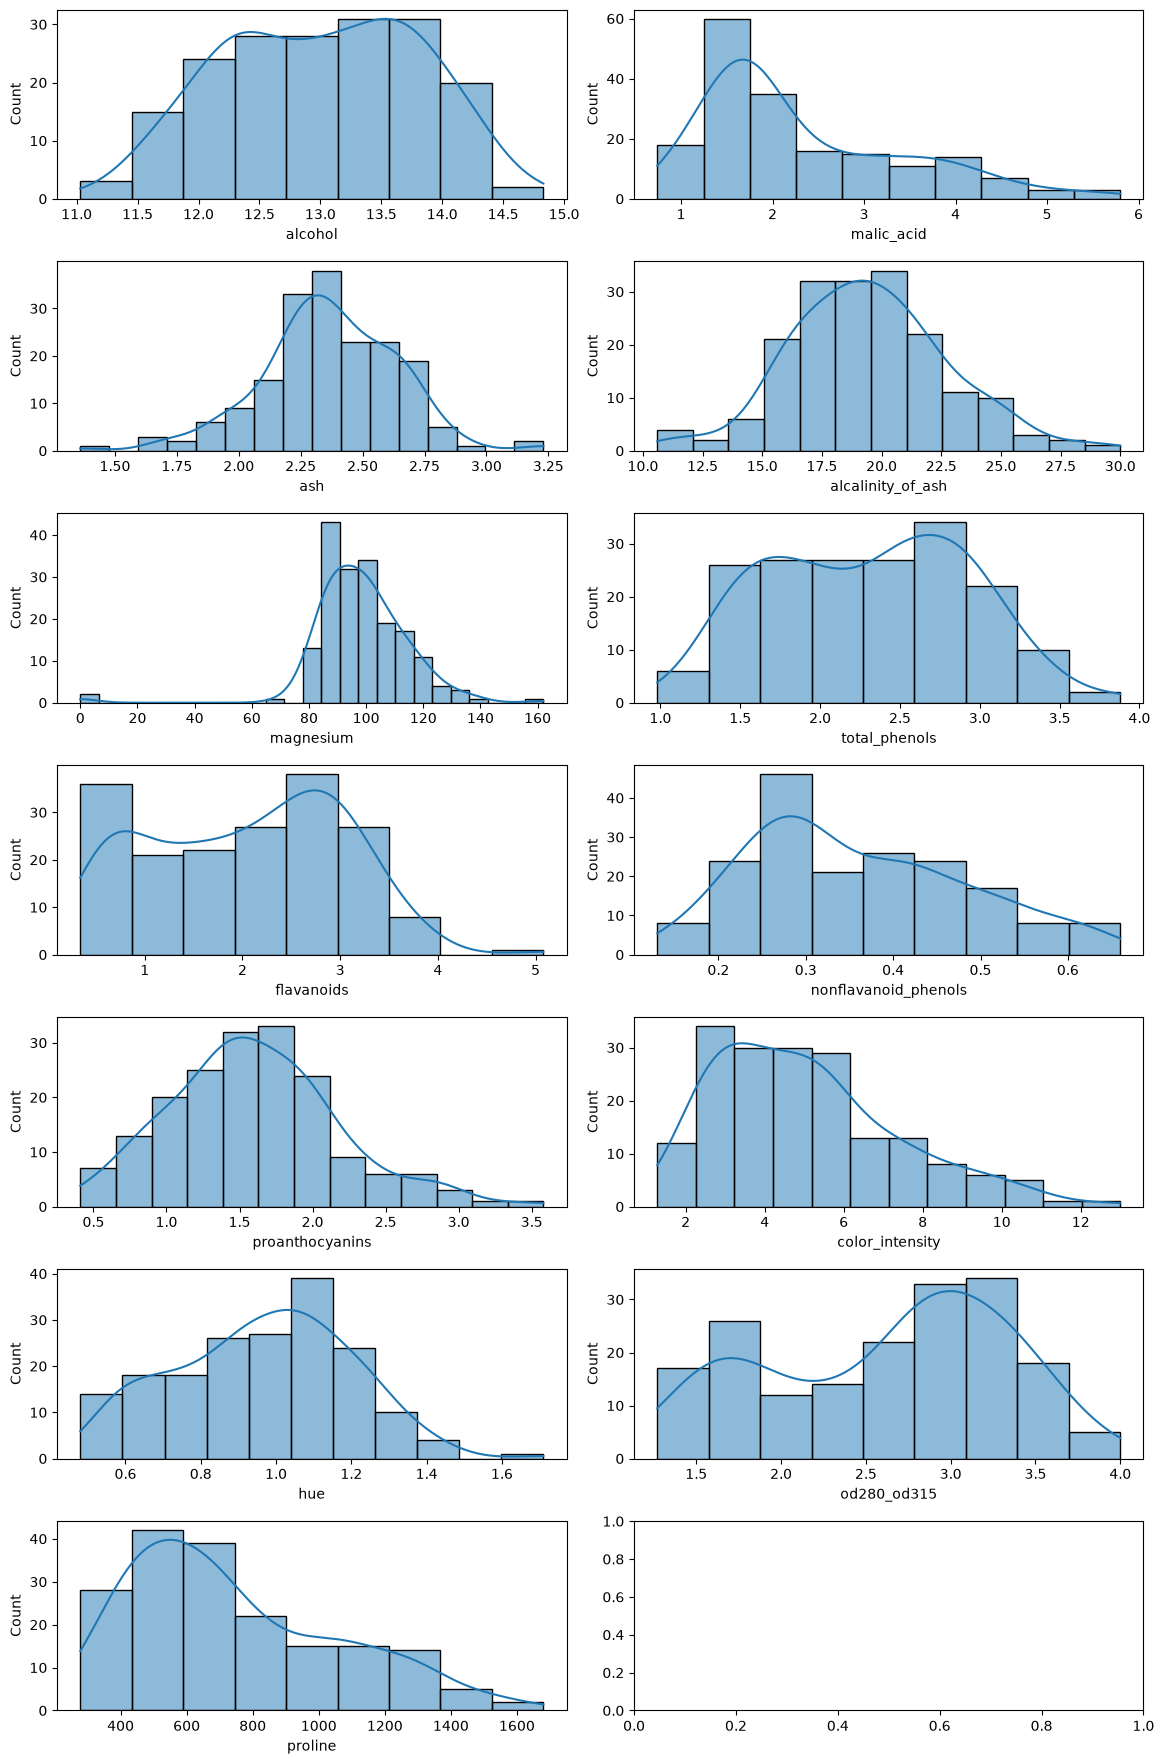

In [10]:
ax, fig = plt.subplots(
    nrows=7,
    ncols=2,
    figsize=(12, 18)
)

for i, col in enumerate(df.columns[:-1]):
    sns.histplot(
        data=df,
        x=col,
        kde=True,
        ax=fig[i // 2, i % 2],
    )

plt.tight_layout(pad=2.0, w_pad=0.5, h_pad=1.0)

### Korelasi

### Masalah kualitas data yang ditemukan
1. Terdapat missing value pada kolom `ash`, `alcalinity_of_ash`, `magnesium`, `total_phenols`, `flavanoids`, `proanthocyanins`, `hue`, `od280_od315`, dan `cultivar`.
2. Terdapat data duplikat sebanyak 4.

## 4. Data Cleaning

Lakukan pembersihan data **tanpa menghitung statistik dari data** (belum boleh imputasi). Simpan hasilnya di `df_clean` dan cetak ukuran sebelum dan sesudah:
- hapus baris duplikat;
- ubah nilai yang mustahil menjadi `NaN`;
- hapus baris yang kelas (`cultivar`)-nya kosong, lalu ubah `cultivar` menjadi bilangan bulat.

### Hapus baris duplikat

In [11]:
df_clean = df.drop_duplicates().copy()
print(f"Jumlah data setelah sebelum duplikat dihapus: {len(df)} | Sesudah: {len(df_clean)}")


Jumlah data setelah sebelum duplikat dihapus: 182 | Sesudah: 178


### Ubah nilai mustahil menjadi `NaN`

In [12]:
# untuk class column
df_clean.loc[
    ~df_clean["cultivar"].isin([1, 2, 3]),
    "cultivar"
] = np.nan

# untuk semua fitur
features = df_clean.columns.drop("cultivar")
df_clean[features] = df_clean[features].mask(df_clean[features] <= 0)

df_clean = df_clean.dropna(subset=['cultivar']).copy()
df_clean["cultivar"] = df_clean["cultivar"].astype(int)

print(f"Ukuran akhir dataset: {len(df_clean)}")

Ukuran akhir dataset: 176


## 5. Split Data Latih dan Data Uji

Bagi `df_clean` menjadi `train_df` dan `test_df` dengan rasio **80:20**, `random_state=42`, dan `stratify` berdasarkan `cultivar`. Gunakan `.copy()` pada keduanya.

> **Penting (anti-data leakage):** statistik apa pun yang dipelajari dari data (median, rata-rata, dsb.) hanya boleh dihitung dari data **latih**.

In [13]:
train_df, test_df = train_test_split(
    df_clean,
    test_size=0.2,
    random_state=42,
    stratify=df_clean["cultivar"]
)

train_df = train_df.copy()
test_df = test_df.copy()

print(f"Ukuran data latih: {train_df.shape}")
print(f"Ukuran data uji: {test_df.shape}")

print("\nDistribusi kelas data latih:")
print(train_df["cultivar"].value_counts())

print("\nDistribusi kelas data uji:")
print(test_df["cultivar"].value_counts())

Ukuran data latih: (140, 14)
Ukuran data uji: (36, 14)

Distribusi kelas data latih:
cultivar
2    56
1    47
3    37
Name: count, dtype: int64

Distribusi kelas data uji:
cultivar
2    14
1    12
3    10
Name: count, dtype: int64


## 6. Imputasi Missing Value

Isi *missing value* pada seluruh kolom fitur dengan **median data latih**, lalu terapkan **nilai median yang sama** ke `train_df` **dan** `test_df`.

**Buktikan** tidak ada missing value yang tersisa.

In [14]:
df_clean = df_clean.fillna(train_df.median(numeric_only=True))
print(f"\nJumlah missing value setelah diisi dengan median: {df_clean.isna().sum().sum()}")
train_df.update(df_clean)
test_df.update(df_clean)

print(f"\nMissing value pada data latih: {train_df.isna().sum().sum()}")
print(f"Missing value pada data uji: {test_df.isna().sum().sum()}")


Jumlah missing value setelah diisi dengan median: 0

Missing value pada data latih: 0
Missing value pada data uji: 0


## 7. Feature Selection

Gunakan **hanya `train_df`**. Ubah kelas menjadi kode angka (`.astype("category").cat.codes`), gabungkan dengan fitur, dan buat **heatmap korelasi** (berlabel angka). Pilih **8 fitur** dengan |korelasi| tertinggi terhadap kelas, simpan di `fitur_terpilih`.

**Tuliskan fitur terpilih dan satu alasan pemilihannya.**

flavanoids              0.822140
od280_od315             0.788518
total_phenols           0.699834
proline                 0.635234
hue                     0.622038
alcalinity_of_ash       0.543068
nonflavanoid_phenols    0.482986
proanthocyanins         0.435280
malic_acid              0.394126
alcohol                 0.307827
color_intensity         0.298271
magnesium               0.188572
ash                     0.065738
Name: cultivar, dtype: float64
Fitur terpilih: ['flavanoids', 'od280_od315', 'total_phenols', 'proline', 'hue', 'alcalinity_of_ash', 'nonflavanoid_phenols', 'proanthocyanins']


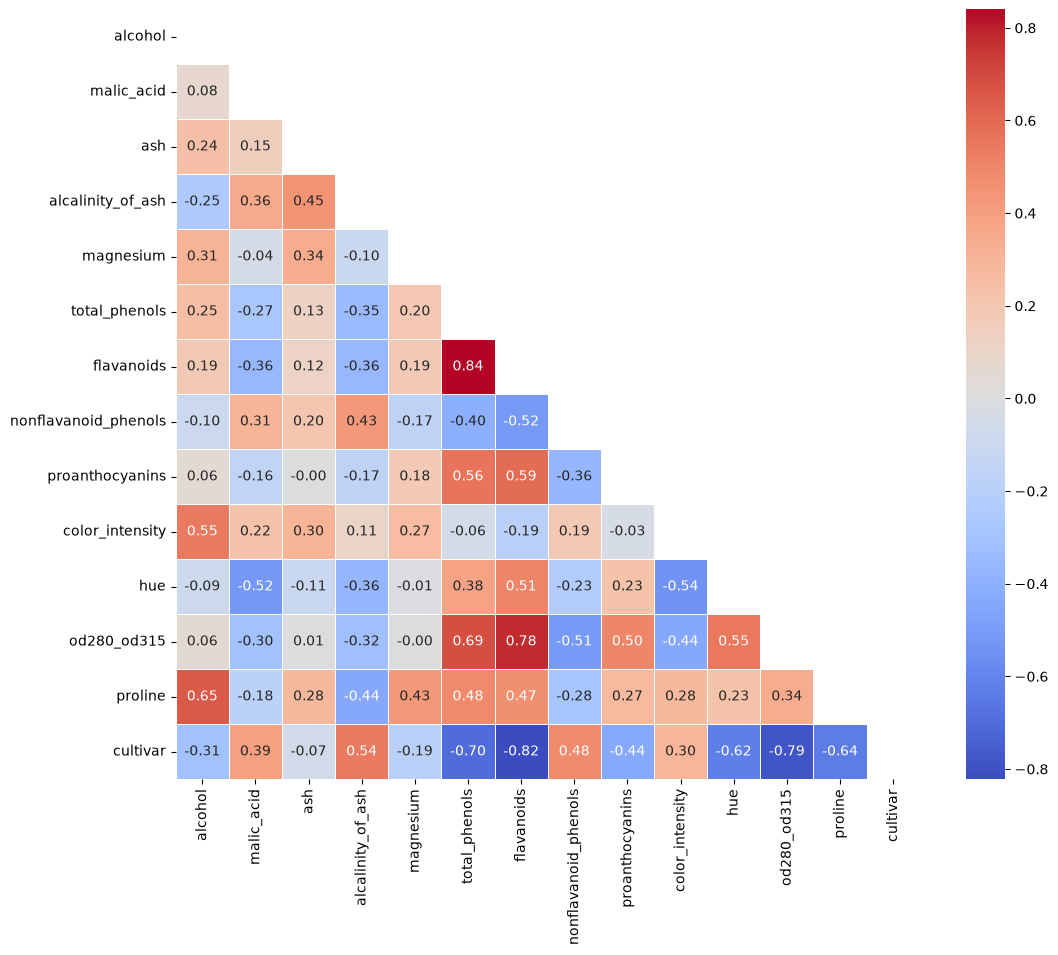

In [23]:
train_corr = train_df.copy()
train_corr["cultivar"] = train_corr["cultivar"].astype("category").cat.codes
corr = train_corr.corr()

plt.figure(figsize=(12, 10))
sns.heatmap(
    corr,
    mask=np.triu(np.ones_like(corr, dtype=bool)),
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    linewidths=0.5
)

corr_target = corr["cultivar"].drop("cultivar").abs().sort_values(ascending=False)
print(corr_target)
fitur_terpilih = corr_target.head(8).index.tolist()
print("Fitur terpilih:", fitur_terpilih)

# A. KLASIFIKASI (target: `cultivar`)

## 8. Model SVM

Buat `X_train`, `X_test`, `y_train`, `y_test` menggunakan `fitur_terpilih` (target `cultivar`). Latih **SVM** dengan kernel linear di dalam `Pipeline` bersama `StandardScaler`.

In [32]:
X_train = train_df[fitur_terpilih]
y_train = train_df["cultivar"]

X_test = test_df[fitur_terpilih]
y_test = test_df["cultivar"]

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.fit_transform(X_test)

model = Pipeline([
    ('scaler', StandardScaler()),
    ('svm', SVC(kernel='linear'))
])
model.fit(X_train, y_train)
y_pred = model.predict(X_test)

result = pd.DataFrame({
    'Actual Label': y_test[:5],
    'Prediksi': y_pred[:5]
})

print(result)

     Actual Label  Prediksi
44              1         1
166             3         3
105             2         2
26              1         1
98              1         1


## 9. Model Random Forest

Latih **Random Forest** (`n_estimators=100`, `max_depth=5`, `random_state=42`) pada data yang sama.

In [36]:
rf_model = RandomForestClassifier(
    n_estimators=100,
    max_depth=5,
    random_state=42
)
rf_model.fit(X_train, y_train)
print("RandomForestClassifier telah dilatih dengan data latih.")

y_pred_rf = rf_model.predict(X_test)
print("\nHasil prediksi dengan RandomForestClassifier:")
result_rf = pd.DataFrame({
    'Actual Label': y_test[:5],
    'Prediksi': y_pred_rf[:5]
})
print(result_rf)

RandomForestClassifier telah dilatih dengan data latih.

Hasil prediksi dengan RandomForestClassifier:
     Actual Label  Prediksi
44              1         1
166             3         3
105             2         2
26              1         1
98              1         1


## 10. Evaluasi Model Klasifikasi

Untuk **kedua model**, tampilkan *confusion matrix* (sebagai plot) dan `classification_report` pada **data uji**.

In [40]:
print("Evaluasi model SVM:")
print(classification_report(y_test, y_pred, target_names=['1', '2', '3']))

print("\nEvaluasi model RandomForestClassifier:")
print(classification_report(y_test, y_pred_rf, target_names=['1', '2', '3']))

Evaluasi model SVM:
              precision    recall  f1-score   support

           1       1.00      1.00      1.00        12
           2       1.00      1.00      1.00        14
           3       1.00      1.00      1.00        10

    accuracy                           1.00        36
   macro avg       1.00      1.00      1.00        36
weighted avg       1.00      1.00      1.00        36


Evaluasi model RandomForestClassifier:
              precision    recall  f1-score   support

           1       0.92      1.00      0.96        12
           2       1.00      0.93      0.96        14
           3       1.00      1.00      1.00        10

    accuracy                           0.97        36
   macro avg       0.97      0.98      0.97        36
weighted avg       0.97      0.97      0.97        36



## 11. Feature Importance

Ambil `feature_importances_` dari Random Forest ke dalam DataFrame (kolom `Feature` dan `Importance`) yang terurut menurun, tampilkan, lalu buat *barplot* dengan seaborn.

,Feature,Importance
0,proline,0.234355
1,flavanoids,0.189445
2,od280_od315,0.184458
3,hue,0.138081
4,total_phenols,0.113433
5,alcalinity_of_ash,0.065404
6,proanthocyanins,0.050458
7,nonflavanoid_phenols,0.024367


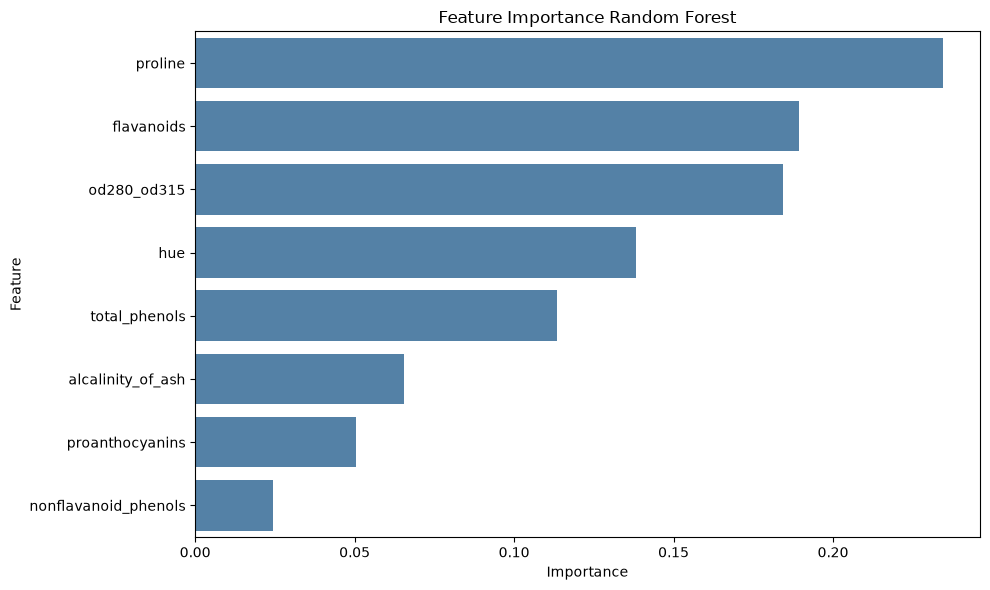

In [42]:
feature_importances = pd.DataFrame({
    'Feature': fitur_terpilih,
    'Importance': rf_model.feature_importances_
}).sort_values(by='Importance', ascending=False).reset_index(drop=True)

display(feature_importances)

plt.figure(figsize=(10, 6))
sns.barplot(
    data=feature_importances,
    x="Importance",
    y="Feature",
    color="steelblue"
)
plt.title("Feature Importance Random Forest")
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

### Pertanyaan Analisis Klasifikasi

**1.** Model mana yang lebih baik berdasarkan akurasi dan F1? Apakah selisihnya cukup berarti, mengingat jumlah data uji?

**2.** Kelas mana yang paling sering salah diprediksi? Berikan satu kemungkinan alasan perbedaan performa kedua model.

**3.** Sebutkan tiga fitur paling berpengaruh menurut Random Forest. Apa artinya bagi tim kontrol kualitas?

1. Berdasarkan akurasi dan F1, model SVM memiliki performa yang lebih baik dibandingkan Random Forest. Selisih akurasi dan F1 antara kedua model tidak terallu signifikan (selisih 0.03), mengingat jumlah data uji yang relatif kecil, sehingga perbedaan ini dapat dianggap tidak terlalu berarti.

2. Kelas yang paling sering salah diprediksi adalah kelas 2, dan hanya pada Random Forest. Alasan yang mungkin membedakan performa adalah kelas 2 memiliki profil senyawa kimia yang mirip dengan keals 1 dan kelas 3, sehingga sampel kelas 2 overlap dengan kelas lain yang membuat model salah prediksi.

3. Tiga fitur paling berpengaruh menurut Random Forest adalah proline (0,234), flavanoids (0,189), dan od280_od315 (0,184), yang bersama-sama menyumbang sekitar 61% dari total importance. Bagi tim kontrol kualitas, artinya ketiga pengukuran ini paling efektif untuk membedakan kultivar wine, sehingga dapat diprioritaskan pada pengecekan rutin atau cepat.

# B. PREDIKSI / REGRESI (target: `alcohol`)

Pada bagian ini kita memprediksi **kadar alkohol** wine dari 12 senyawa kimia lain. Gunakan `train_df` dan `test_df` yang sama (sudah dibersihkan dan diimputasi).

## 12. Menyiapkan Data Prediksi

Tentukan fitur dan target untuk prediksi:
- fitur (`fitur_reg`): seluruh 12 fitur kimia **kecuali** `alcohol` (kelas `cultivar` tidak dipakai);
- target: `alcohol`.

Hitung juga **RMSE tebakan paling sederhana** (selalu menebak rata-rata `alcohol` data latih) sebagai pembanding.

In [20]:
# TODO

## 13. Linear Regression, Ridge, dan Lasso

Latih tiga model di dalam `Pipeline` bersama `StandardScaler`:
- `LinearRegression()`
- `Ridge(alpha=1.0)`
- `Lasso(alpha=0.1)`

In [21]:
# TODO

## 14. Evaluasi dan Koefisien

Pada **data uji**, hitung RMSE dan R² untuk ketiga model. Lalu tampilkan koefisien ketiganya berdampingan, dan hitung berapa koefisien Lasso yang bernilai tepat 0 (sebutkan fiturnya).

In [22]:
# TODO

### Pertanyaan Analisis Prediksi

**1.** Bandingkan RMSE dan R² ketiga model, dan bandingkan dengan tebakan rata-rata. Apakah model prediksi ini cukup baik?

**2.** Apakah Ridge atau Lasso memberi perbaikan yang berarti dibanding Linear Regression? Jelaskan.

**3.** Fitur apa saja yang dipertahankan Lasso, dan apa artinya jika tujuannya menyederhanakan model?

Tulis jawaban di sini.

# C. KESIMPULAN

Tuliskan kesimpulan singkat berdasarkan:
1. hasil klasifikasi (SVM vs Random Forest dan fitur terpentingnya);
2. hasil prediksi (tiga model regresi);
3. satu saran untuk tim kontrol kualitas.

Tulis kesimpulan di sini.